In [1]:
import numpy as np
import pickle
from POSEIDON.core import (create_star, create_planet, define_model,
                            make_atmosphere, compute_spectrum, wl_grid_constant_R)
from POSEIDON.constants import R_J, M_J, R_Sun

with open("freckll_to_poseidon_handoff.pkl", "rb") as f:
    handoff = pickle.load(f)

pressure_bar = handoff["pressure_bar"]
planets = handoff["planets"]
species_names = handoff["species_names"]
equilibrium_vmr = handoff["equilibrium_vmr"]
equilibrium_temperature_K = handoff["equilibrium_temperature_K"]
disequilibrium_vmr = handoff["disequilibrium_vmr"]
n_planets = len(planets["Teq_K"])

def find_species_index(names_list, name):
    for idx, n in enumerate(names_list):
        if n == name:
            return idx
    raise ValueError(f"Species {name} not found")

target_species = ["H2O", "CH4", "CO", "CO2", "NH3"]
species_idx = {name: find_species_index(species_names, name) for name in target_species}

wl_min, wl_max, R_highres = 0.4, 10.0, 15000
wl_highres = wl_grid_constant_R(wl_min, wl_max, R_highres)

OPAC_FILE = "opacities_created/opac_eq_chemistry.pickle"
with open(OPAC_FILE, "rb") as f:
    opac = pickle.load(f)

bulk_species  = ["H2", "He"]
param_species = ["H2O", "CH4", "CO", "CO2", "NH3"]

model = define_model(
    "sidequest_freckll_model", bulk_species, param_species,
    PT_profile="file_read", X_profile="file_read",
)

star = create_star(1.0 * R_Sun, 5778.0, 4.44, 0.0)
print(f"Loaded handoff: {n_planets} planets. Model and star defined.")

Loaded handoff: 10 planets. Model and star defined.


In [2]:
pressure_bar_fixed = pressure_bar[::-1]
def build_X_input(vmr_array, s_idx):
    h2_profile = np.full(len(pressure_bar_fixed), 0.83)
    he_profile = np.full(len(pressure_bar_fixed), 0.17)
    return np.array([
        h2_profile, he_profile,
        vmr_array[s_idx["H2O"], :], vmr_array[s_idx["CH4"], :],
        vmr_array[s_idx["CO"], :],  vmr_array[s_idx["CO2"], :],
        vmr_array[s_idx["NH3"], :],
    ])

spectra_results = []

for i in range(n_planets):
    T_input = equilibrium_temperature_K[i]
    Rp = planets["Rp_Rj"][i]
    Mp = planets["Mp_Mj"][i]
    Teq = planets["Teq_K"][i]

    R_p = Rp * R_J
    M_p = Mp * M_J
    planet = create_planet("sidequest_planet", R_p, mass=M_p, T_eq=Teq)
    P_ref = 10.0

    planet_spectra = {}
    cases = {"equilibrium": equilibrium_vmr[i]}
    for label in ["low", "med", "high"]:
        vmr_array = disequilibrium_vmr[i][label]
        if vmr_array is not None:
            cases[label] = vmr_array

    for case_label, vmr_array in cases.items():
        X_input = build_X_input(vmr_array, species_idx)
        x_input_order = ["H2", "He", "H2O", "CH4", "CO", "CO2", "NH3"]
        for row_i, name in enumerate(x_input_order):
            v = X_input[row_i, :]
            print(f"Planet {i} [{case_label}] {name}: min={v.min():.3e}, max={v.max():.3e}")
        atmosphere = make_atmosphere(planet, model, pressure_bar_fixed, P_ref, R_p,
                                      T_input=T_input, X_input=X_input)

        print("is_physical:", atmosphere["is_physical"])
        print("P range:", atmosphere["P"].min(), atmosphere["P"].max())
        print("T range:", atmosphere["T"].min(), atmosphere["T"].max())
        for key in ["H2O", "CH4", "CO", "CO2", "NH3"]:
            if key in atmosphere:
                print(key, "min/max:", atmosphere[key].min(), atmosphere[key].max())

        print("pressure_bar[:5]:", pressure_bar[:5])
        print("pressure_bar[-5:]:", pressure_bar[-5:])
        if not atmosphere["is_physical"]:
            print(f"Planet {i:2d} [{case_label:11s}]: SKIPPED — atmosphere not physical")
            continue

        spectrum_hires = compute_spectrum(planet, star, model, atmosphere,
                                           opac, wl_highres, spectrum_type="transmission")

        if np.any(np.isnan(spectrum_hires)) or np.any(np.isinf(spectrum_hires)):
            print(f"Planet {i:2d} [{case_label:11s}]: SKIPPED — NaN/Inf in spectrum")
            continue

        planet_spectra[case_label] = spectrum_hires
        print(f"Planet {i:2d} [{case_label:11s}]: spectrum computed, shape={spectrum_hires.shape}")

    spectra_results.append(planet_spectra)

with open("spectra_checkpoint.pkl", "wb") as f:
    pickle.dump(spectra_results, f)

Planet 0 [equilibrium] H2: min=8.300e-01, max=8.300e-01
Planet 0 [equilibrium] He: min=1.700e-01, max=1.700e-01
Planet 0 [equilibrium] H2O: min=3.644e-12, max=5.232e-04
Planet 0 [equilibrium] CH4: min=1.663e-30, max=2.384e-05
Planet 0 [equilibrium] CO: min=2.261e-04, max=4.180e-04
Planet 0 [equilibrium] CO2: min=3.791e-12, max=4.207e-08
Planet 0 [equilibrium] NH3: min=1.618e-22, max=7.324e-06
is_physical: True
P range: 1e-08 100.0
T range: 2389.6710780240815 2389.6710780240815
pressure_bar[:5]: [1.00000000e-08 1.26185688e-08 1.59228279e-08 2.00923300e-08
 2.53536449e-08]
pressure_bar[-5:]: [ 39.44206059  49.77023564  62.80291442  79.24828984 100.        ]
Planet  0 [equilibrium]: spectrum computed, shape=(48283,)
Planet 0 [low] H2: min=8.300e-01, max=8.300e-01
Planet 0 [low] He: min=1.700e-01, max=1.700e-01
Planet 0 [low] H2O: min=4.776e-11, max=5.225e-04
Planet 0 [low] CH4: min=5.583e-29, max=2.325e-05
Planet 0 [low] CO: min=2.261e-04, max=4.180e-04
Planet 0 [low] CO2: min=1.373e-11, 

Planet 0 [equilibrium]: mean=6.935812e-03, std=2.965992e-05, min=6.851667e-03, max=6.974047e-03
Planet 0 [low]: mean=6.939342e-03, std=2.929455e-05, min=6.853041e-03, max=6.975293e-03
Planet 0 [med]: mean=6.939460e-03, std=2.923586e-05, min=6.853275e-03, max=6.975307e-03
Planet 0 [high]: mean=6.945945e-03, std=2.385357e-05, min=6.865770e-03, max=6.975729e-03
Planet 1 [equilibrium]: mean=3.828444e-02, std=3.180525e-04, min=3.737994e-02, max=3.871165e-02
Planet 1 [med]: mean=3.828567e-02, std=3.180033e-04, min=3.737996e-02, max=3.871220e-02
Planet 1 [high]: mean=3.858090e-02, std=3.915632e-04, min=3.740149e-02, max=3.923443e-02
Planet 2 [equilibrium]: mean=1.885637e-02, std=1.110278e-04, min=1.857783e-02, max=1.902667e-02
Planet 2 [med]: mean=1.888045e-02, std=1.165389e-04, min=1.857941e-02, max=1.905181e-02
Planet 2 [high]: mean=1.888882e-02, std=1.168981e-04, min=1.858341e-02, max=1.905949e-02
Planet 3 [equilibrium]: mean=3.009324e-02, std=1.751020e-04, min=2.949941e-02, max=3.029651e-

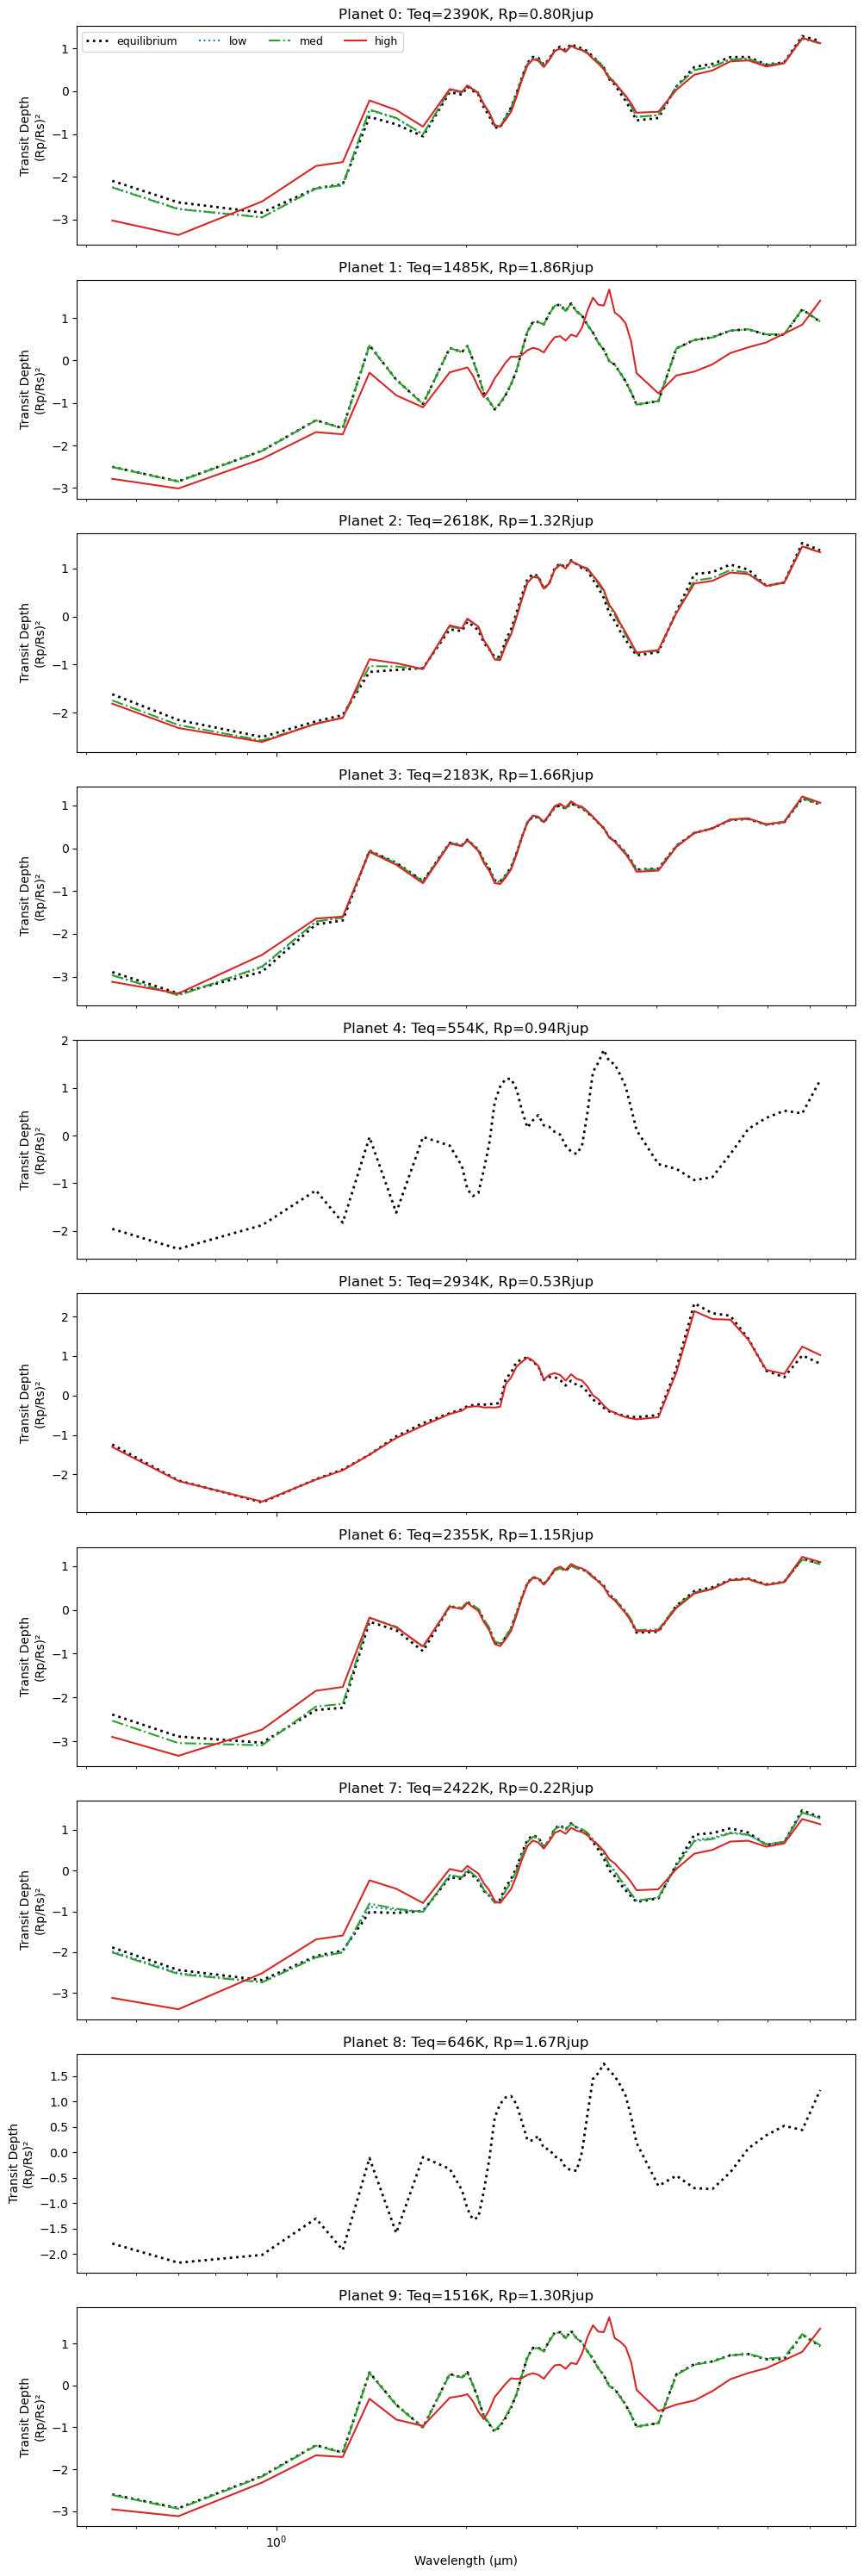

In [ ]:
import spectres
import matplotlib.pyplot as plt

with open("spectra_checkpoint.pkl", "rb") as f:
    spectra_results = pickle.load(f)

wl_binned = np.load("equi_chem_data/wl_binned.npy")

case_styles = {
    "equilibrium": dict(color="black", ls=":", lw=2),
    "low":  dict(color="tab:blue",  ls="--"),
    "med":  dict(color="tab:green", ls="-."),
    "high": dict(color="tab:red",   ls="-"),
}

fig, axes = plt.subplots(n_planets, 1, figsize=(10, 3* n_planets), sharex=True)

for i in range(n_planets):
    ax = axes[i]
    for case_label, spectrum_hires in spectra_results[i].items():
        spectrum_binned = spectres.spectres(wl_binned, wl_highres, spectrum_hires, verbose=False)
        print(f"Planet {i} [{case_label}]: mean={spectrum_binned.mean():.6e}, std={spectrum_binned.std():.6e}, min={spectrum_binned.min():.6e}, max={spectrum_binned.max():.6e}")
        spectrum_binned = (spectrum_binned - spectrum_binned.mean()) / (spectrum_binned.std() + 1e-8)
        style = case_styles[case_label]
        ax.plot(wl_binned, spectrum_binned, label=case_label, **style)

    ax.set_ylabel("Transit Depth\n(Rp/Rs)²")
    ax.set_title(f"Planet {i}: Teq={planets['Teq_K'][i]:.0f}K, Rp={planets['Rp_Rj'][i]:.2f}Rjup")
    if i == 0:
        ax.legend(ncol=4, fontsize=9)

axes[-1].set_xlabel("Wavelength (μm)")
axes[-1].set_xscale("log")

plt.tight_layout()
plt.savefig("spectra_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

In [4]:
import pickle
import numpy as np

with open("spectra_checkpoint.pkl", "rb") as f:
    spectra_results = pickle.load(f)

s = spectra_results[0]["equilibrium"]
print("shape:", s.shape, "dtype:", s.dtype)
print("raw max - min:", s.max() - s.min())
print("first 5 values:", s[:5])
print("middle 5 values:", s[24000:24005])
print("last 5 values:", s[-5:])

shape: (48283,) dtype: float64
raw max - min: 0.00022485534033012382
first 5 values: [0.00689137 0.00689136 0.00689136 0.00689135 0.00689135]
middle 5 values: [0.00693551 0.00690397 0.00697727 0.0069068  0.00693459]
last 5 values: [0.00698727 0.00695225 0.00696444 0.0069914  0.00693498]


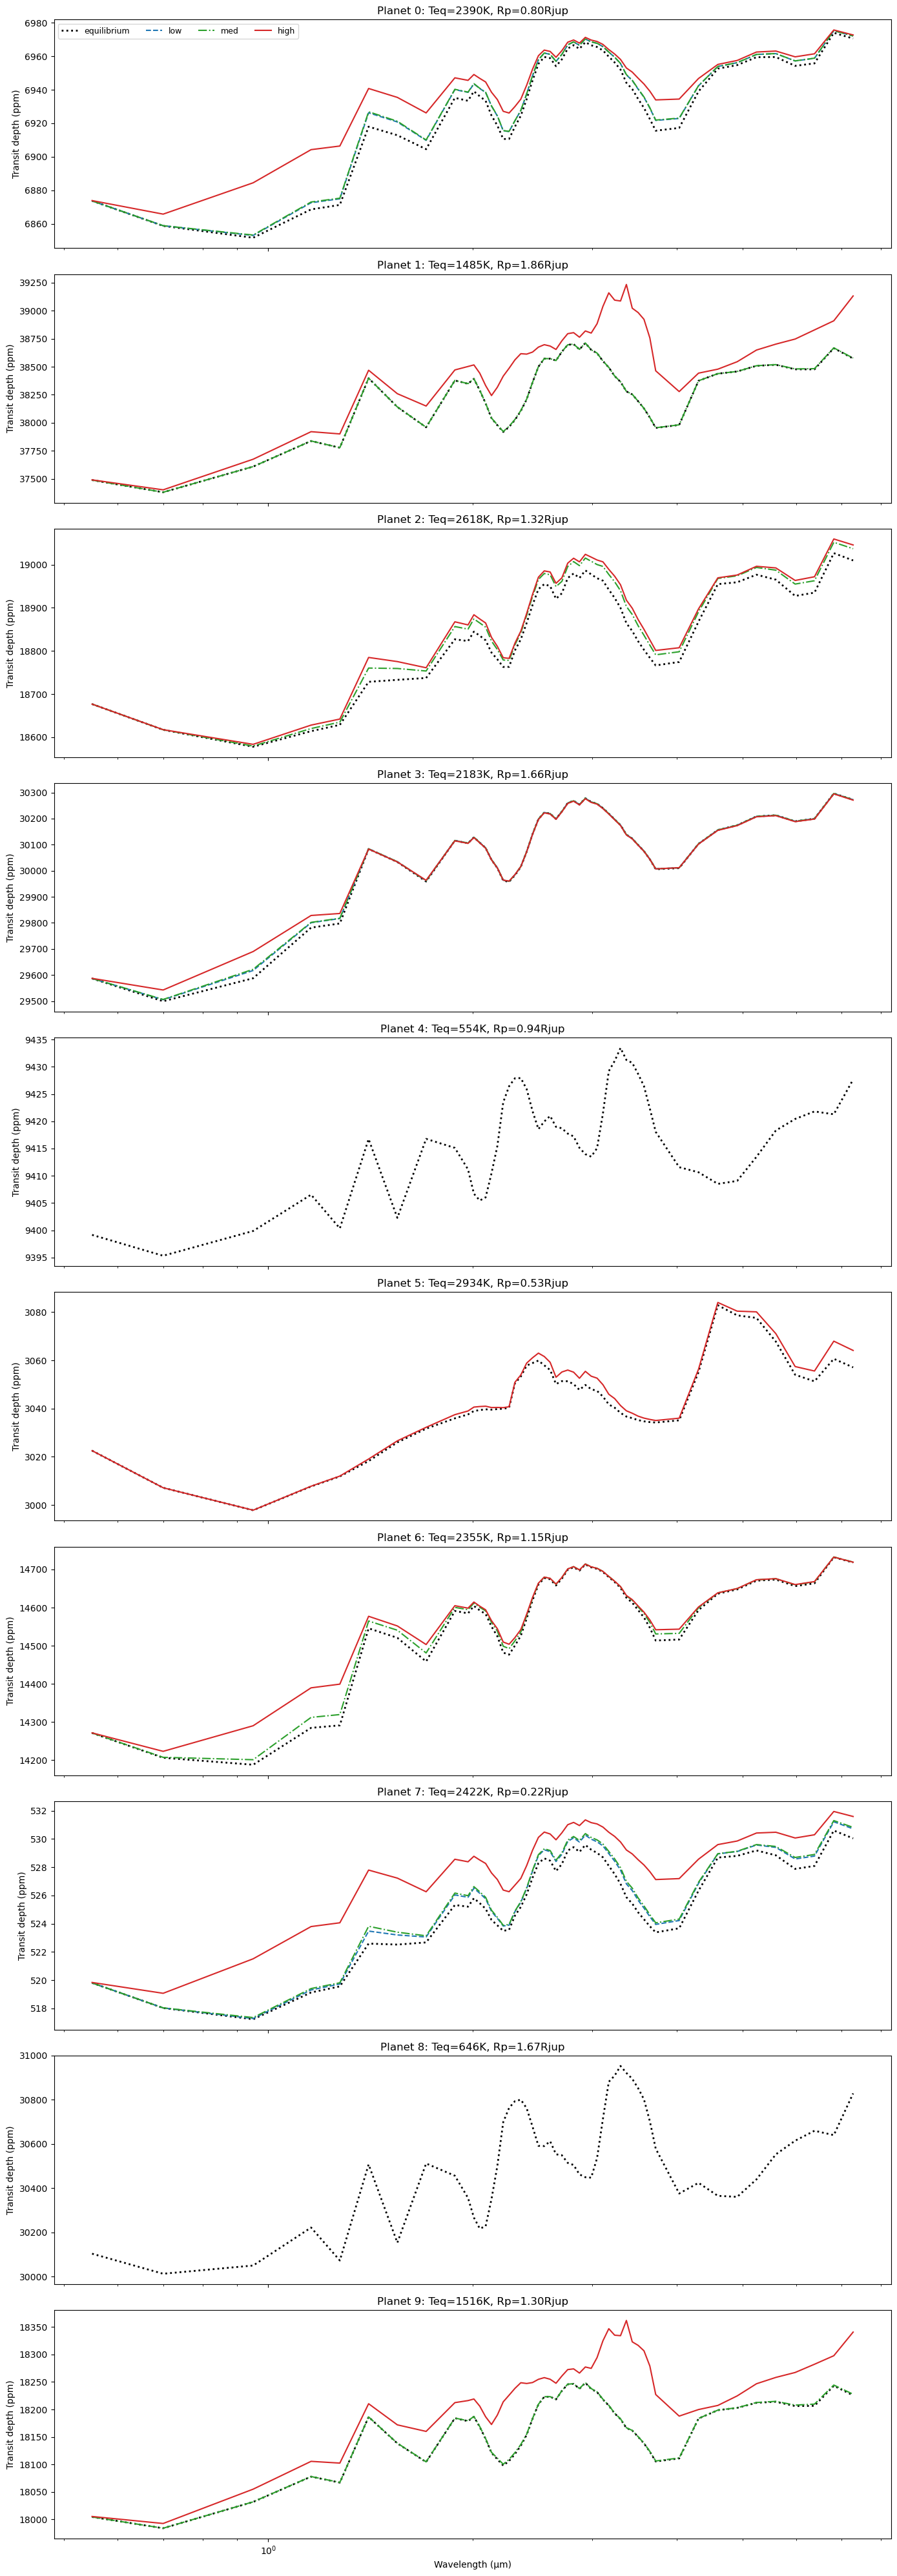

In [5]:
import spectres
import numpy as np
import matplotlib.pyplot as plt

with open("spectra_checkpoint.pkl", "rb") as f:
    spectra_results = pickle.load(f)

wl_binned = np.load("equi_chem_data/wl_binned.npy")

case_styles = {
    "equilibrium": dict(color="black", ls=":", lw=2),
    "low":  dict(color="tab:blue",  ls="--"),
    "med":  dict(color="tab:green", ls="-."),
    "high": dict(color="tab:red",   ls="-"),
}

fig, axes = plt.subplots(n_planets, 1, figsize=(14, 4 * n_planets), sharex=True)

for i in range(n_planets):
    ax = axes[i]
    for case_label, spectrum_hires in spectra_results[i].items():
        spectrum_binned = spectres.spectres(wl_binned, wl_highres, spectrum_hires, verbose=False)
        depth_ppm = spectrum_binned * 1e6   # (Rp/Rs)^2 in ppm, NOT normalized
        ax.plot(wl_binned, depth_ppm, label=case_label, **case_styles[case_label])
    ax.set_ylabel("Transit depth (ppm)")
    ax.set_title(f"Planet {i}: Teq={planets['Teq_K'][i]:.0f}K, Rp={planets['Rp_Rj'][i]:.2f}Rjup")
    if i == 0:
        ax.legend(ncol=4, fontsize=9)

axes[-1].set_xlabel("Wavelength (μm)")
axes[-1].set_xscale("log")
plt.tight_layout()
plt.savefig("spectra_comparison_fixed.png", dpi=150, bbox_inches="tight")
plt.show()

In [6]:
print("opac T_fine range:", opac["T_fine"].min(), opac["T_fine"].max())
print("opac log_P_fine range:", opac["log_P_fine"].min(), opac["log_P_fine"].max())

# compare against what your atmospheres actually span
print("atmosphere T values seen: 554K to 2934K")
print("atmosphere P range: 1e-8 to 100 bar  →  log10(P):", np.log10(1e-8), "to", np.log10(100))

opac T_fine range: 300 3000
opac log_P_fine range: -8.0 2.000000000000009
atmosphere T values seen: 554K to 2934K
atmosphere P range: 1e-8 to 100 bar  →  log10(P): -8.0 to 2.0


In [7]:
print(len(wl_highres), wl_highres.min(), wl_highres.max())
print(opac["sigma_stored"].shape)  

48283 0.4 10.0
(5, 51, 271, 48283)


In [8]:
print(type(opac))
if isinstance(opac, dict):
    print("Keys:", list(opac.keys()))
    for k, v in opac.items():
        print(f"  {k}: type={type(v)}", getattr(v, "shape", ""))
print("wl_highres range:", wl_highres.min(), "-", wl_highres.max())

<class 'dict'>
Keys: ['opacity_database', 'opacity_treatment', 'sigma_stored', 'CIA_stored', 'Rayleigh_stored', 'eta_stored', 'ff_stored', 'bf_stored', 'T_fine', 'log_P_fine', 'database_version', 'aerosol_stored']
  opacity_database: type=<class 'str'> 
  opacity_treatment: type=<class 'str'> 
  sigma_stored: type=<class 'numpy.ndarray'> (5, 51, 271, 48283)
  CIA_stored: type=<class 'numpy.ndarray'> (6, 271, 48283)
  Rayleigh_stored: type=<class 'numpy.ndarray'> (7, 48283)
  eta_stored: type=<class 'numpy.ndarray'> (7, 48283)
  ff_stored: type=<class 'numpy.ndarray'> (0, 271, 48283)
  bf_stored: type=<class 'numpy.ndarray'> (0, 48283)
  T_fine: type=<class 'numpy.ndarray'> (271,)
  log_P_fine: type=<class 'numpy.ndarray'> (51,)
  database_version: type=<class 'str'> 
  aerosol_stored: type=<class 'dict'> 
wl_highres range: 0.4 - 10.0


In [9]:
print(spectrum_hires.max() - spectrum_hires.min())

0.000645697042393735
